# 3. Downstream Analysis for Alzheimer’s Disease Dataset

In this tutorial, we demonstrate how to perform downstream analysis using the multi-scale results generated by **SpatialZoomer**.

For illustration, we use a Xenium v1 Alzheimer’s disease dataset containing **349,063 cells and 347 genes**. This dataset includes **six mouse brain samples**, including wild-type samples (**WT1, WT2, and WT3**) and TgCRND8 Alzheimer’s disease mouse model samples (**Tg1, Tg2, and Tg3**) collected at three time points, corresponding to mild, moderate, and advanced stages of amyloid-beta (Aβ) deposition.

The data integration and preprocessing steps have been completed in `1_Data_preparation_Xenium_V1_AD_Merged.ipynb`, and the multi-scale feature analysis using SpatialZoomer has been completed in `2_Multi-scale_Analysis_Xenium_V1_AD_Merged.ipynb`. 

**Users can either load the previously generated AnnData object or download the processed AnnData object from [Google Drive](https://drive.google.com/file/d/19iSZ3OHdBq2nldGF6OG5SaIeEblqRBXO/view?usp=drive_link).**

Information about the original raw data is available from the official 10x Genomics data release: [Xenium v1 Alzheimer’s disease dataset](https://www.10xgenomics.com/datasets/xenium-in-situ-analysis-of-alzheimers-disease-mouse-model-brain-coronal-sections-from-one-hemisphere-over-a-time-course-1-standard).


### 0. Load packages and data

Load the ST data, perform quality control on cells and genes, and apply normalization.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
import pandas as pd

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 6,
    'pdf.fonttype': 42,
    "figure.dpi": 80,      
    "savefig.dpi": 300      
    })
use_dpi = 80 
sc.settings.set_figure_params(dpi=150)


In [2]:
runLabel = 'Xenium_V1_AD_Merged'
save_path = './Outputs/'
adata = sc.read_h5ad("./" + runLabel+ "_SpatialZoomer.h5ad")
adata

AnnData object with n_obs × n_vars = 349063 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'Kmeans_scale1.1', 'leiden_scale1.1_res0.8', 'leiden_scale1.1_res1', 'Kmeans_scale3.0', 'leiden_scale3.0_res0.8', 'leiden_scale3.0_res1', 'Kmeans_scale4.5', 'leiden_scale4.5_res0.8', 'leiden_scale4.5_res1', 'Kmeans_scale6.0', 'leiden_scale6.0_res0.8', 'leiden_scale6.0_res1', 'Kmeans_scale8.0', 'leiden_scale8.0_res0.8', 'leiden_scale8.0_res1', 'Kmeans_scale10.5', 'leiden_scale10.5_res0.8', 'leiden_scale10.5

## Adjust spatial coordinates for better visualization

In [3]:
# Extract original spatial coordinates for each sample
spatial_w1 = adata.obsm["spatial_raw"][adata.obs['batch'] == 'WT1'].copy()
spatial_w2 = adata.obsm["spatial_raw"][adata.obs['batch'] == 'WT2'].copy()
spatial_w3 = adata.obsm["spatial_raw"][adata.obs['batch'] == 'WT3'].copy()
spatial_t1 = adata.obsm["spatial_raw"][adata.obs['batch'] == 'TgCRND81'].copy()
spatial_t2 = adata.obsm["spatial_raw"][adata.obs['batch'] == 'TgCRND82'].copy()
spatial_t3 = adata.obsm["spatial_raw"][adata.obs['batch'] == 'TgCRND83'].copy()

# Rotate and flip individual samples for better visual alignment
# WT1
spatial_w1[:, 0] = -spatial_w1[:, 0]  # Flip along the x-axis
rotation_matrix = np.array([[0, 1],
                            [-1, 0]])
spatial_w1_rotated = spatial_w1 @ rotation_matrix

# Shift coordinates to ensure samples are well separated
shift_x = abs(spatial_w1_rotated[:, 0].min()) + abs(spatial_w1_rotated[:, 0].max())
shift_y = abs(spatial_w1_rotated[:, 1].min()) + abs(spatial_w1_rotated[:, 1].max())
spatial_w1_rotated[:, 0] += shift_x
spatial_w1_rotated[:, 1] += shift_y


# WT2
rotation_matrix = np.array([[0, 1],
                            [-1, 0]])
spatial_w2_rotated = spatial_w2 @ rotation_matrix

shift_x = abs(spatial_w2_rotated[:, 0].min()) + abs(spatial_w2_rotated[:, 0].max())
spatial_w2_rotated[:, 0] += shift_x


# WT3
spatial_w3[:, 0] = -spatial_w3[:, 0]  # Flip along the x-axis
rotation_matrix = np.array([[0, 1],
                            [-1, 0]])
spatial_w3_rotated = spatial_w3 @ rotation_matrix

shift_x = abs(spatial_w3_rotated[:, 0].min()) + abs(spatial_w3_rotated[:, 0].max())
shift_y = abs(spatial_w3_rotated[:, 1].min()) + abs(spatial_w3_rotated[:, 1].max())
spatial_w3_rotated[:, 0] += shift_x
spatial_w3_rotated[:, 1] += shift_y


# TgCRND81
rotation_matrix = np.array([[0, -1],
                            [1, 0]])
spatial_t1_rotated = spatial_t1 @ rotation_matrix

shift_y = abs(spatial_t1_rotated[:, 1].min()) + abs(spatial_t1_rotated[:, 1].max())
spatial_t1_rotated[:, 1] += shift_y


# TgCRND82
rotation_matrix = np.array([[0, -1],
                            [1, 0]])
spatial_t2_rotated = spatial_t2 @ rotation_matrix

shift_y = abs(spatial_t2_rotated[:, 1].min()) + abs(spatial_t2_rotated[:, 1].max())
spatial_t2_rotated[:, 1] += shift_y


# TgCRND83
rotation_matrix = np.array([[0, 1],
                            [-1, 0]])
spatial_t3_rotated = spatial_t3 @ rotation_matrix
spatial_t3_rotated[:, 0] = -spatial_t3_rotated[:, 0]


# Arrange WT and TgCRND8 samples into two columns
padding = 300
max_x = np.max([
    spatial_w1_rotated[:, 0].max(),
    spatial_w2_rotated[:, 0].max(),
    spatial_w3_rotated[:, 0].max()
])
offset_x = max_x + padding

spatial_t1_rotated[:, 0] += offset_x
spatial_t2_rotated[:, 0] += offset_x
spatial_t3_rotated[:, 0] += offset_x


# Arrange the three time points vertically
padding = 180

max_y2 = np.max([
    spatial_w1_rotated[:, 1].max(),
    spatial_t1_rotated[:, 1].max()
])
offset_y2 = max_y2 + padding

spatial_w2_rotated[:, 1] += offset_y2
spatial_t2_rotated[:, 1] += offset_y2

max_y3 = np.max([
    spatial_w2_rotated[:, 1].max(axis=0),
    spatial_t2_rotated[:, 1].max(axis=0)
])
offset_y3 = max_y3 + padding

spatial_w3_rotated[:, 1] += offset_y3
spatial_t3_rotated[:, 1] += offset_y3


# Fine-tune sample positions for better visualization
spatial_w1_rotated[:, 0] += 250
spatial_t1_rotated[:, 1] += 100
spatial_t3_rotated[:, 1] += 100


# Update spatial coordinates used for visualization
adata.obsm["spatial"][adata.obs['batch'] == 'WT1'] = spatial_w1_rotated.copy()
adata.obsm["spatial"][adata.obs['batch'] == 'WT2'] = spatial_w2_rotated.copy()
adata.obsm["spatial"][adata.obs['batch'] == 'WT3'] = spatial_w3_rotated.copy()
adata.obsm["spatial"][adata.obs['batch'] == 'TgCRND81'] = spatial_t1_rotated.copy()
adata.obsm["spatial"][adata.obs['batch'] == 'TgCRND82'] = spatial_t2_rotated.copy()
adata.obsm["spatial"][adata.obs['batch'] == 'TgCRND83'] = spatial_t3_rotated.copy()

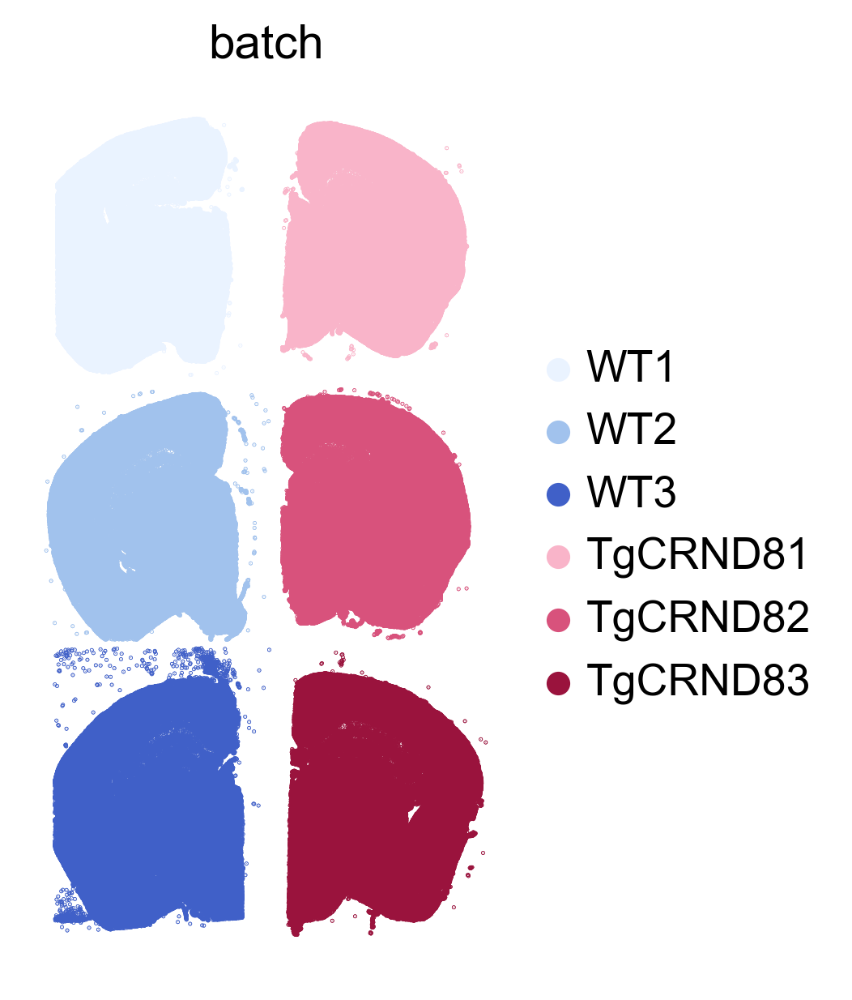

In [4]:
adata.uns['batch_colors'] = np.array(['#EAF3FFFF', '#A1C2EDFF', '#4060C8FF', '#F9B4C9FF', '#D8527CFF', '#9A133DFF'])

# Visualize the adjusted spatial layout
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color='batch',
    wspace=0.1,
    frameon=False,
    size=0.1,
)

load cell morphology information

In [5]:
samples = ["WT1", "WT2", "WT3", "TgCRND81", "TgCRND82", "TgCRND83"]

cell_morphology = pd.read_csv(f"Xenium_V1_AD_Merged_morphology_information.csv", index_col=0)
adata.obs_names = adata.obs_names.astype(str)
cell_morphology.index = cell_morphology.index.astype(str)

new_columns = cell_morphology.columns.difference(adata.obs.columns, sort=False)
adata.obs = pd.concat([adata.obs, cell_morphology[new_columns].reindex(adata.obs_names)], axis=1)

## Reset colors for consistent visualization across samples

To facilitate visual comparison across scales and sections, we adjust cluster colors based on a reference clustering result. Target clusters are assigned colors according to their overlap with the reference clusters, so that corresponding spatial structures are shown with similar colors whenever possible.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, to_rgb


# Check whether any two colors in a palette are too similar.
def check_color_similarity(colors, threshold=0.1):
    rgb_colors = np.array([to_rgb(color) for color in colors])
    similar_pairs = []

    for i in range(len(rgb_colors)):
        for j in range(i + 1, len(rgb_colors)):
            dist = np.linalg.norm(rgb_colors[i] - rgb_colors[j])
            if dist < threshold:
                similar_pairs.append((colors[i], colors[j], dist))

    return similar_pairs


# Adjust target cluster colors based on overlap with a reference clustering.
def adjust_target_colors_from_ref(adata, reference_cluster, target_cluster, use_colors):
    adata.obs[reference_cluster] = adata.obs[reference_cluster].astype("category")
    adata.obs[target_cluster] = adata.obs[target_cluster].astype("category")

    ref_categories = list(adata.obs[reference_cluster].cat.categories)
    tgt_categories = list(adata.obs[target_cluster].cat.categories)

    ref_color_key = f"{reference_cluster}_colors"
    if ref_color_key not in adata.uns:
        raise ValueError(f"Colors for {reference_cluster} not found in `adata.uns`.")

    ref_colors = list(adata.uns[ref_color_key])
    ref_color_mapping = dict(zip(ref_categories, ref_colors))

    # Compute overlap between reference clusters and target clusters
    overlap = pd.crosstab(
        adata.obs[reference_cluster],
        adata.obs[target_cluster]
    )

    tgt_color_mapping = {}
    used_colors = set()

    # Assign each reference color to the target cluster with the largest overlap
    for ref_cluster in ref_categories:
        if ref_cluster in overlap.index:
            main_tgt_cluster = overlap.loc[ref_cluster].idxmax()

            if main_tgt_cluster not in tgt_color_mapping:
                color = ref_color_mapping[ref_cluster]
                tgt_color_mapping[main_tgt_cluster] = color
                used_colors.add(color)

    # Assign unused colors to unmatched target clusters
    remaining_colors = [c for c in use_colors if c not in used_colors]

    for tgt_cluster in tgt_categories:
        if tgt_cluster not in tgt_color_mapping:
            if len(remaining_colors) == 0:
                raise ValueError("Not enough colors available to assign all target clusters.")
            tgt_color_mapping[tgt_cluster] = remaining_colors.pop(0)

    adata.uns[f"{target_cluster}_colors"] = [
        tgt_color_mapping[cluster] for cluster in tgt_categories
    ]

    # print(f"Colors for {target_cluster} were updated successfully.")


# Remove colors that are too similar.
def filter_similar_colors(colors, threshold=0.1):
    filtered_colors = []

    for color in colors:
        if all(np.linalg.norm(color - fc) >= threshold for fc in filtered_colors):
            filtered_colors.append(color)

    return np.array(filtered_colors)


# Generate a palette with enough distinct colors.
def generate_colors(num_colors):
    np.random.seed(0)

    cmap_list = [plt.cm.tab20, plt.cm.tab20b, plt.cm.tab20c, plt.cm.tab10, plt.cm.Paired, plt.cm.Set3]

    colors = np.vstack([
        cmap(np.linspace(0, 1, cmap.N))[:, :3]
        for cmap in cmap_list
    ])

    while len(colors) < num_colors:
        additional_colors = np.random.rand(num_colors - len(colors), 3)
        colors = np.vstack([colors, additional_colors])

    new_colors = filter_similar_colors(colors, threshold=0.1)

    while len(new_colors) < num_colors:
        additional_colors = np.random.rand(num_colors - len(new_colors), 3)
        colors = np.vstack([new_colors, additional_colors])
        new_colors = filter_similar_colors(colors, threshold=0.1)

    return new_colors[:num_colors]

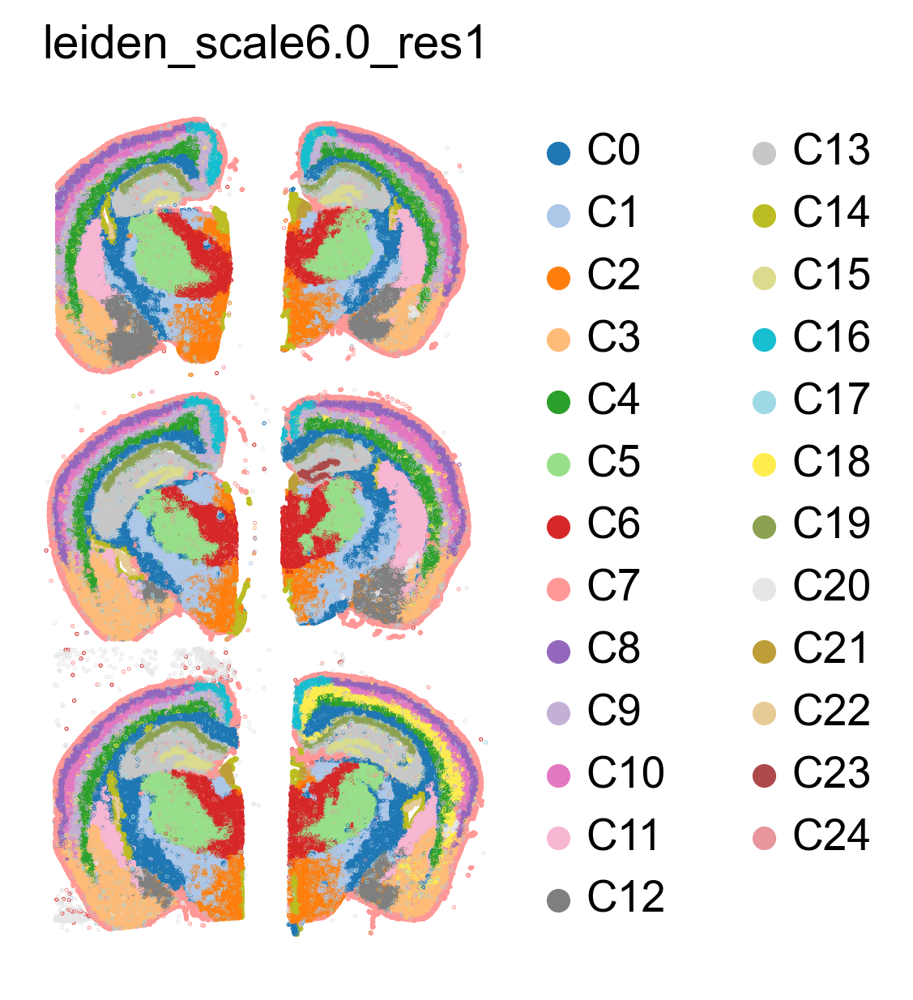

In [7]:
colors = [
    "#1f77b4", "#aec7e8", "#ff7f0e", "#ffbb78", "#2ca02c", "#98df8a",
    "#d62728", "#ff9896", "#9467bd", "#c5b0d5", "#e377c2", "#f7b6d2",
    "#7f7f7f", "#c7c7c7", "#bcbd22", "#dbdb8d", "#17becf", "#9edae5",
    "#FFED4D", "#8ca252", "#E6E6E6", "#bd9e39", "#e7cb94", "#ad494a", "#e7969c"
]

adata.uns["leiden_scale6.0_res1_colors"] = colors

# Visualize the adjusted spatial layout
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color='leiden_scale6.0_res1',
    wspace=0.1,
    frameon=False,
    size=0.1,
)

In [8]:
import re
from matplotlib.colors import to_hex

# Match Leiden clustering columns across scales and resolutions
pattern = re.compile(r"^leiden_scale[0-9.]+_res[0-9.]+$")

target_cols = [
    c for c in adata.obs.columns
    if pattern.match(c)
]

reference_cluster = "leiden_scale6.0_res1"

# Use the colors from the reference clustering
use_colors = generate_colors(200)
use_colors = [to_hex(color) for color in use_colors]

for target_cluster in target_cols:
    adjust_target_colors_from_ref(
        adata,
        reference_cluster=reference_cluster,
        target_cluster=target_cluster,
        use_colors=use_colors,
    )

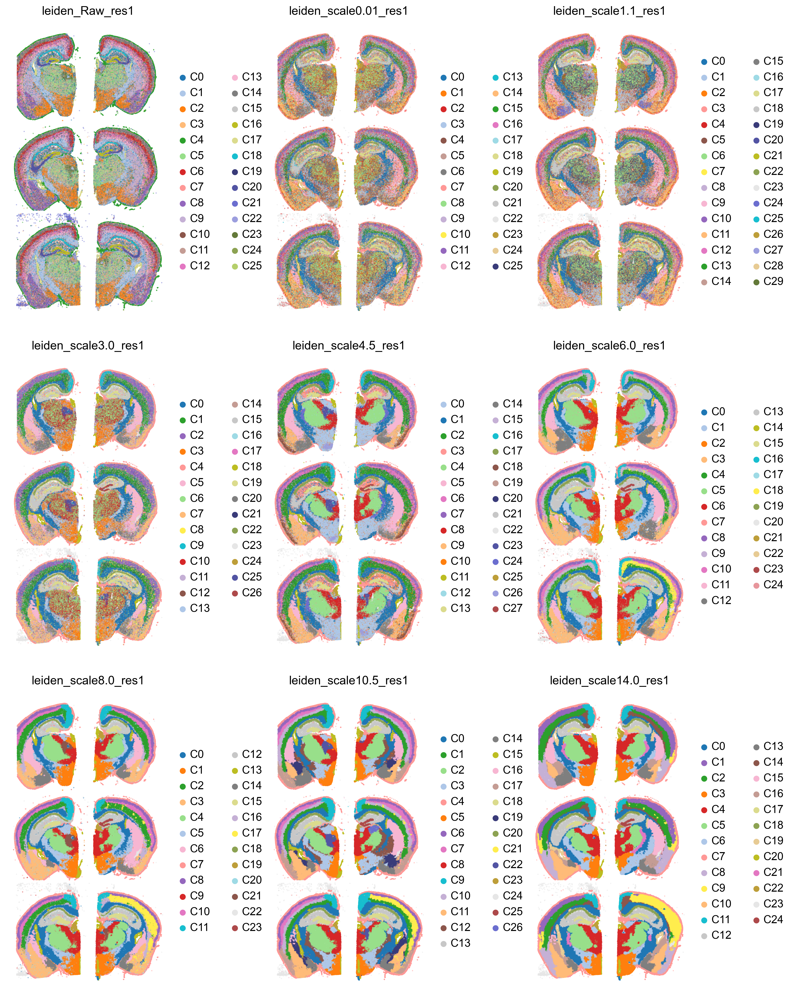

In [9]:
import math
import matplotlib.pyplot as plt
import squidpy as sq

leiden_cols = [col for col in adata.obs.columns if col.startswith("leiden") and col.endswith("res1")][:9]

# Plot spatial maps, 3 panels per row
ncols = 3
nrows = math.ceil(len(leiden_cols) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4.5 * ncols, 5.5 * nrows),
)

axes = axes.flatten()

for i, col in enumerate(leiden_cols):
    sq.pl.spatial_scatter(
        adata,
        library_id="spatial",
        shape=None,
        color=col,
        wspace=0.1,
        frameon=False,
        size=0.1,
        ax=axes[i],
    )
    axes[i].set_title(col)

# Remove empty panels
for j in range(len(leiden_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## Cell type and domain annotation

### Cell type annotation

We compute differentially expressed genes for each cluster and use them together with known marker genes to guide cell type annotation. Here, we provide a simplified example of this annotation process by also considering the spatial distribution of each cluster.

In [10]:
sc.tl.rank_genes_groups(adata, groupby="leiden_Raw_res1", method="wilcoxon")

# Extract differential expression results
results = adata.uns["rank_genes_groups"]
groups = results["names"].dtype.names

# Store differential expression results for each group in a DataFrame
ranked_genes = []
for group in groups:
    group_df = pd.DataFrame({
        "group": group,
        "gene": results["names"][group],
        "logfoldchanges": results["logfoldchanges"][group],
        "pvals": results["pvals"][group],
        "pvals_adj": results["pvals_adj"][group],
        "scores": results["scores"][group],
    })
    ranked_genes.append(group_df)

# Combine differential expression results from all groups
all_ranked_genes = pd.concat(ranked_genes, axis=0).reset_index(drop=True)

# Extract the top 10 marker genes for each group
result = []
for cell_type in all_ranked_genes["group"].unique():
    top_genes = all_ranked_genes[
        all_ranked_genes["group"] == cell_type
    ]["gene"].head(10)
    genes_string = ",".join(top_genes)
    result_string = f"{cell_type}: {genes_string}"
    result.append(result_string)

# Print the top marker genes for each group
for line in result:
    print(line)

C0: Gja1,Apoe,Clu,Ntsr2,Prdx6,Sparcl1,Cst3,Acsbg1,Cd63,Slc39a12
C1: Plp1,Mobp,Mbp,Cnp,Apod,Gatm,Plekhb1,Cryab,Gjc3,Opalin
C2: Vat1l,Rmst,Dner,Tmem255a,Calb2,Hpcal1,Nr2f2,Rasgrf2,Plcxd3,Gad2
C3: Cldn5,Ly6a,Adgrl4,Fn1,Pecam1,Emcn,Acvrl1,Cst3,Sparcl1,Kdr
C4: Igf2,Apod,Dcn,Aldh1a2,B2m,Fn1,Vim,Slc13a4,Col1a1,Ifitm3
C5: Ntng1,Slc17a6,Nell1,Rims3,Clmn,Prox1,Tmem163,Tanc1,Rnf152,Foxp2
C6: Mef2c,Nrn1,Kcnh5,Plcxd2,Nrep,Satb2,Rims3,Rorb,Epha4,Neurod6
C7: Hexb,Ctss,Csf1r,C1qa,C1qb,P2ry12,Ctsd,C1qc,Cx3cr1,Laptm5
C8: Cpne6,Slc17a7,2010300C02Rik,Mef2c,Hpcal1,Bhlhe22,Rprm,Nrn1,Dner,Gucy1a1
C9: Meis2,Penk,Wfs1,Ppp1r1b,Gad1,Gad2,Pde7b,2010300C02Rik,Bcl11b,Necab2
C10: Gad1,Gad2,Dner,Rab3b,Kcnmb2,Zfp536,Col19a1,Syngr1,Btbd11,Neto2
C11: Plp1,Cnp,Mobp,Apod,Gatm,Mbp,Gjc3,Cryab,Clmn,Opalin
C12: Dpy19l1,Slc17a7,Dkk3,Mef2c,Syngr1,Neurod6,Satb2,Hs3st2,Sorl1,Nrn1
C13: Garnl3,Dkk3,Tle4,Slc17a7,Grik3,Rprm,Nxph3,Fezf2,Hs3st2,Syngr1
C14: Lamp5,Mef2c,Cux2,Rasgrf2,Gucy1a1,Calb1,2010300C02Rik,Slc17a7,Nrn1,Pdzrn3
C15: Pd

In [11]:
import pandas as pd
from collections import Counter

# cell type annotation
cluster_to_celltype = {
    "C0": "Astrocyte",
    "C1": "Oligo1",
    "C2": "Inh1",
    "C3": "Endothelial",
    "C4": "VLMC",
    "C5": "Ex1",
    "C6": "Ex2",
    "C7": "Microglia",
    "C8": "Ex3",
    "C9": "Inh2",
    "C10": "Inh3",
    "C11": "Oligo2",
    "C12": "Ex4",
    "C13": "Ex5",
    "C14": "Ex6",
    "C15": "OPC",
    "C16": "Ex7",
    "C17": "Ependymal",
    "C18": "Ex8",
    "C19": "Oligo3",
    "C20": "Ex9",
    "C21": "Unassigned",
    "C22": "Ex10",
    "C23": "Ex11",
    "C24": "Ex12",
    "C25": "Inh4",
}

# Annotate cell types based on Leiden cluster labels
adata.obs["Final_Cell_Type"] = (
    adata.obs["leiden_Raw_res1"]
    .astype(str)
    .map(cluster_to_celltype)
)

# Convert to categorical type with the desired display order
new_order = [
    "Microglia", "Astrocyte", "Endothelial", "Ependymal", "VLMC",
    "OPC", "Oligo1", "Oligo2", "Oligo3",
    "Ex1", "Ex2", "Ex3", "Ex4", "Ex5", "Ex6", "Ex7", "Ex8", "Ex9", "Ex10", "Ex11", "Ex12",
    "Inh1", "Inh2", "Inh3", "Inh4", "Unassigned"
]

adata.obs["Final_Cell_Type"] = pd.Categorical(
    adata.obs["Final_Cell_Type"],
    categories=new_order,
    ordered=True
)


from collections import Counter
print(Counter(adata.obs['Final_Cell_Type']))

Counter({'Astrocyte': 41594, 'Oligo1': 40736, 'Inh1': 32867, 'Endothelial': 26297, 'VLMC': 17539, 'Ex1': 16897, 'Ex2': 16200, 'Microglia': 15102, 'Ex3': 13897, 'Inh2': 13313, 'Inh3': 12945, 'Oligo2': 12865, 'Ex4': 12662, 'Ex5': 12412, 'Ex6': 12302, 'OPC': 10245, 'Ex7': 9485, 'Ependymal': 7347, 'Ex8': 5265, 'Oligo3': 5041, 'Ex9': 4082, 'Unassigned': 3097, 'Ex10': 2129, 'Ex11': 1897, 'Ex12': 1736, 'Inh4': 1111})


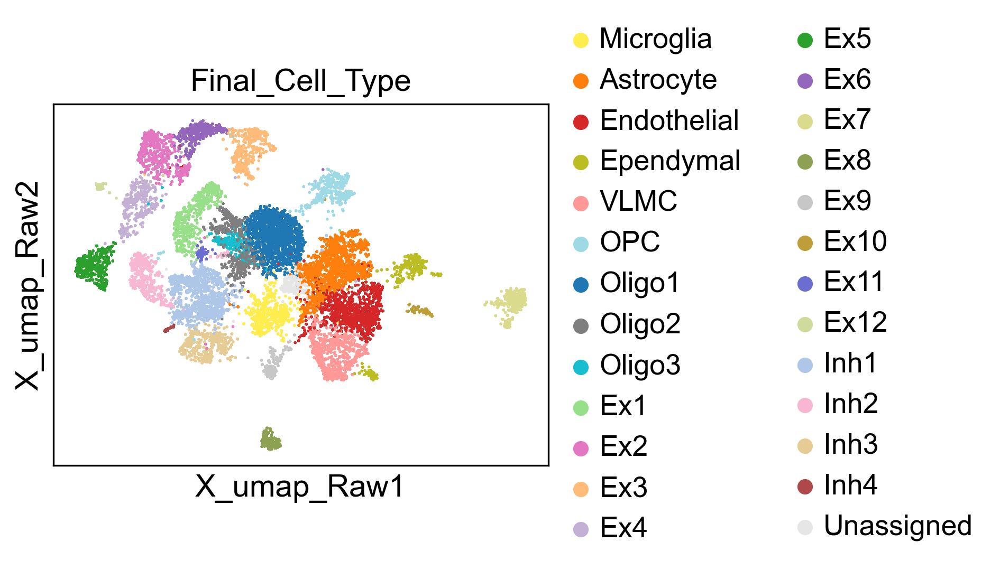

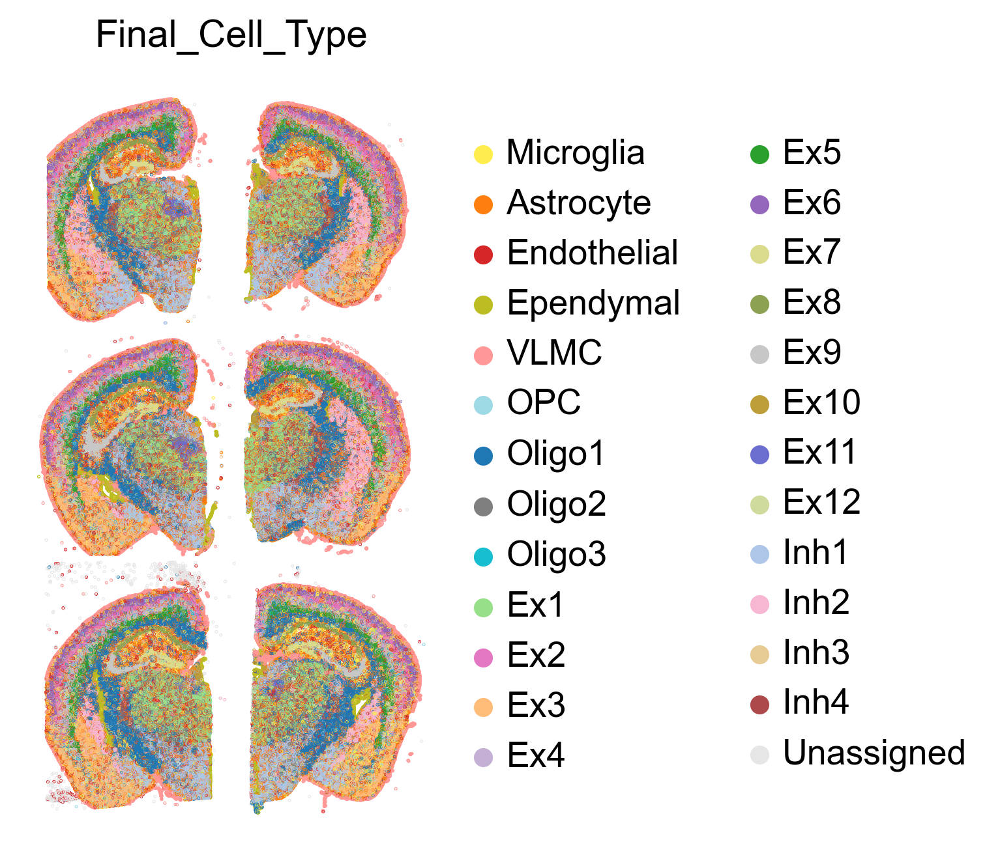

In [12]:
cell_type_colors = ['#FFED4DFF', '#ff7f0e', '#d62728', '#bcbd22', '#ff9896', '#9edae5',
                    '#1f77b4', '#7f7f7f', '#17becf', '#98df8a', '#e377c2', '#ffbb78',
                    '#c5b0d5', '#2ca02c', '#9467bd', '#dbdb8d', '#8ca252', '#c7c7c7',
                    '#bd9e39', '#6b6ecf', '#cedb9c', '#aec7e8', '#f7b6d2', '#e7cb94',
                    '#ad494a', '#E6E6E6FF']

adata.uns['Final_Cell_Type_colors'] = cell_type_colors


fig, ax = plt.subplots(figsize=(4, 3))
sc.pl.embedding(
    adata,
    basis="X_umap_Raw",
    color="Final_Cell_Type",
    size=6,
    ax=ax,
    show=False,
)
plt.show()

sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color="Final_Cell_Type",
    frameon=False,
    size=0.1,
    figsize=(5, 10)
)


### Brain domain annotation

We annotate brain domains by considering both spatial locations and cell-type composition, using the [Allen Brain Map](https://atlas.brain-map.org/atlas?atlas=602630314) as a reference.

In [13]:
import pandas as pd
from collections import Counter

# Copy the reference clustering result for brain domain annotation
adata.obs["Domain"] = adata.obs["leiden_scale6.0_res1"].astype("category")

# Rename Leiden clusters as brain domains
new_cluster_names = [
    "Fiber tracts",        # 0
    "RT/PAL",              # 1
    "HY",                  # 2
    "OLF/CTXsp",           # 3
    "L6",                  # 4
    "TH-DORsm",            # 5
    "TH-DORpm",            # 6
    "Meninges/L1",         # 7
    "L2/3",                # 8
    "L5",                  # 9
    "L4",                  # 10
    "CP",                  # 11
    "sAMY",                # 12
    "CA2/CA3/CAsim",       # 13
    "VL/V3",               # 14
    "DG",                  # 15
    "RSP",                 # 16
    "OPC in CH",           # 17
    "Progression-related", # 18
    "CA1",                 # 19
    "Unassigned",          # 20
    "MH",                  # 21
    "chpl",                # 22
    "DG (Tg2)",            # 23
    "OPC in BS",           # 24
]

adata.rename_categories("Domain", new_cluster_names)

# Check the number of cells in each annotated brain domain
# Counter(adata.obs["Domain"])

# Define the display order of brain domains
new_order = [
    "Progression-related", "Meninges/L1", "L2/3", "L4", "L5", "L6",
    "Fiber tracts", "RSP", "OLF/CTXsp",
    "CP", "sAMY", "VL/V3",
    "CA1", "CA2/CA3/CAsim", "DG", "DG (Tg2)",
    "RT/PAL", "HY", "MH", "chpl",
    "OPC in BS", "OPC in CH", "TH-DORsm", "TH-DORpm", "Unassigned"
]

# Reorder categories for consistent visualization
adata.obs["Domain"] = pd.Categorical(
    adata.obs["Domain"],
    categories=new_order,
    ordered=True
)

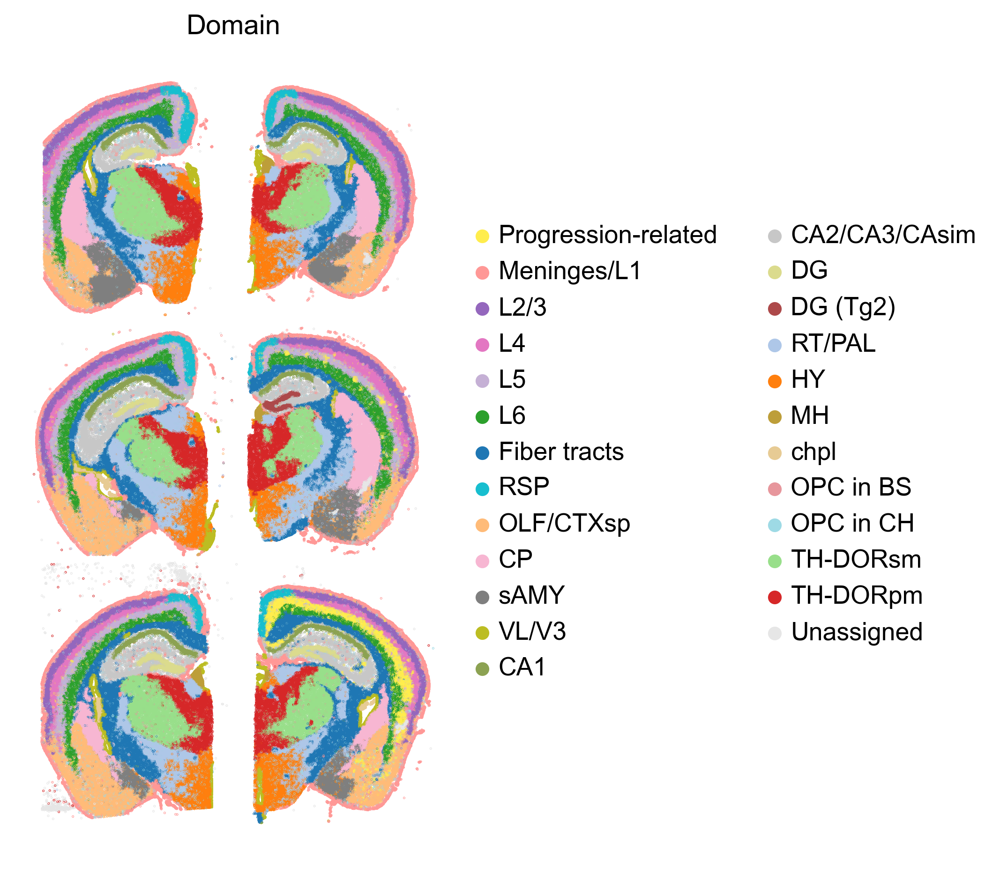

In [14]:
adjust_target_colors_from_ref(
    adata,
    reference_cluster=reference_cluster,
    target_cluster='Domain',
    use_colors=use_colors,
)

sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color="Domain",
    frameon=False,
    size=0.1,
    figsize=(7, 10)
)

## Proportions of conditions within each cluster across scales

In [15]:
# Plot horizontal stacked bar charts showing the composition of a given annotation within each cluster.
def plot_cell_type_proportion_horizontal(
    adata,
    leiden_col,
    cell_type_col,
    title="Proportions",
    figsize=(8, 5),
    fontsize=6,
    save_path=None,
    ax=None,
    show=True,
    legend=True
):
    df = adata.obs[[leiden_col, cell_type_col]]
    count_df = df.groupby([leiden_col, cell_type_col]).size().unstack(fill_value=0)
    proportion_df = count_df.div(count_df.sum(axis=1), axis=0)

    cell_type_colors = adata.uns.get(cell_type_col + "_colors", None)
    if cell_type_colors is None:
        cell_type_colors = plt.cm.tab20.colors[:len(proportion_df.columns)]
    else:
        if len(cell_type_colors) < len(proportion_df.columns):
            raise ValueError(
                "The number of colors is smaller than the number of categories. "
                "Please check the color definition in `adata.uns`."
            )

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    proportion_df.plot(
        kind="barh",
        stacked=True,
        color=cell_type_colors,
        width=0.75,
        grid=False,
        ax=ax
    )

    ax.set_title(title, fontsize=fontsize)
    ax.set_ylabel("")
    ax.set_xlabel("Proportion", fontsize=fontsize)
    ax.invert_yaxis()
    ax.axvline(0.5, color="#EEE9E9", linestyle="--", linewidth=1)
    ax.tick_params(axis="both", labelsize=fontsize)

    for spine in ax.spines.values():
        spine.set_linewidth(0.5)

    if legend:
        ax.legend(
            title="",
            bbox_to_anchor=(1.02, 0.5),
            loc="center left",
            borderaxespad=0,
            fontsize=fontsize,
            frameon=False
        )
    else:
        if ax.get_legend() is not None:
            ax.get_legend().remove()

    if save_path is not None:
        plt.savefig(save_path, format="pdf", bbox_inches="tight")

    if show:
        plt.show()

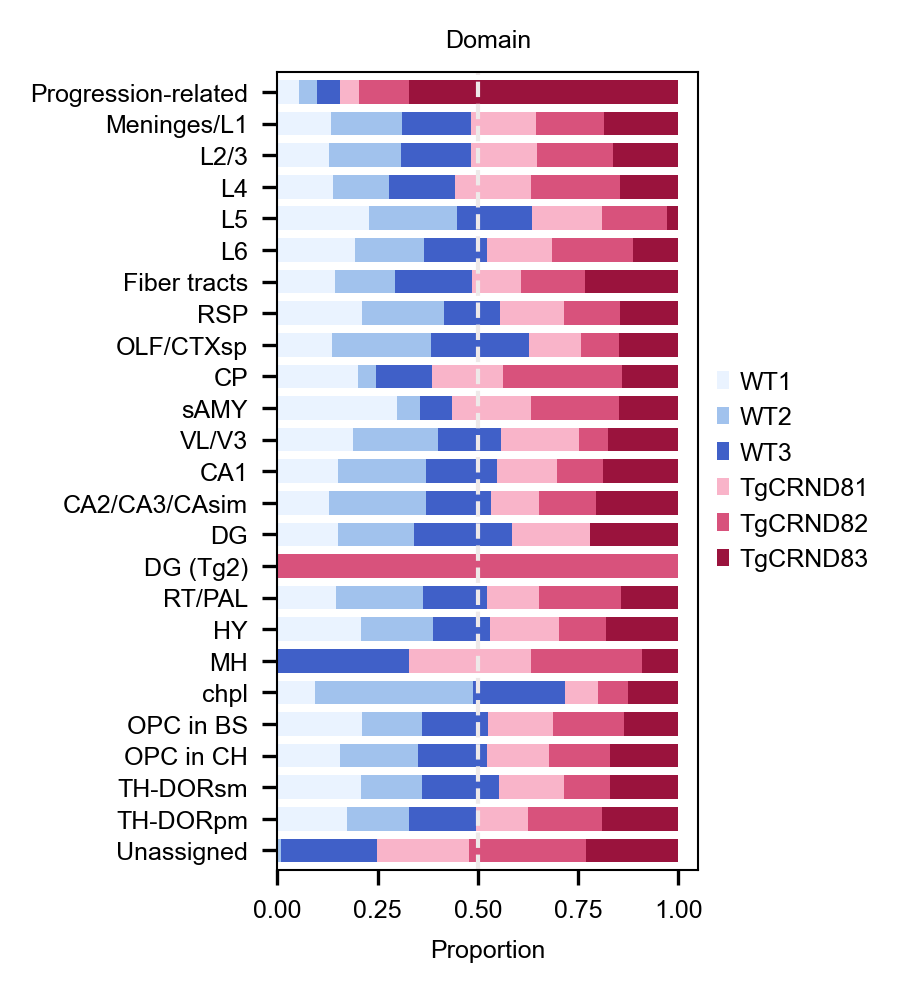

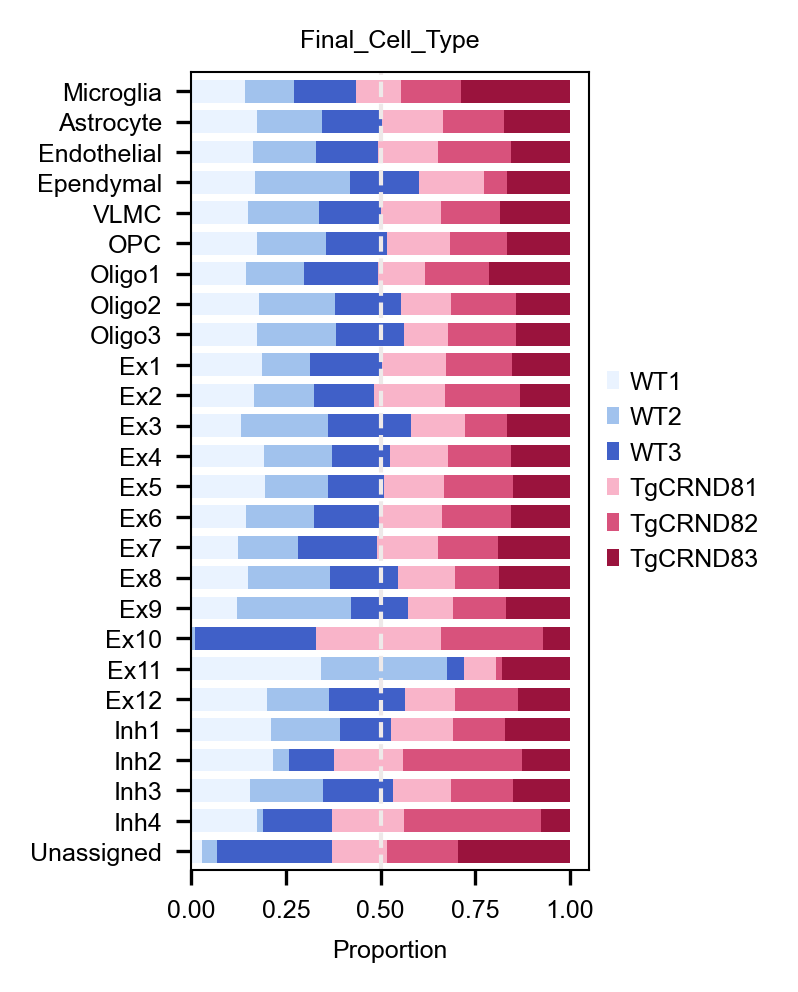

In [16]:
leiden_col = 'Domain'
plot_cell_type_proportion_horizontal(adata, leiden_col=leiden_col, cell_type_col='batch', figsize=(1.8, 3.5), title=leiden_col, save_path=save_path + '/' + leiden_col + '_proportion_horizontal.pdf')

leiden_col = 'Final_Cell_Type'
plot_cell_type_proportion_horizontal(adata, leiden_col=leiden_col, cell_type_col='batch', figsize=(1.7, 3.5), title=leiden_col, save_path=save_path + '/' + leiden_col + '_proportion_horizontal.pdf')


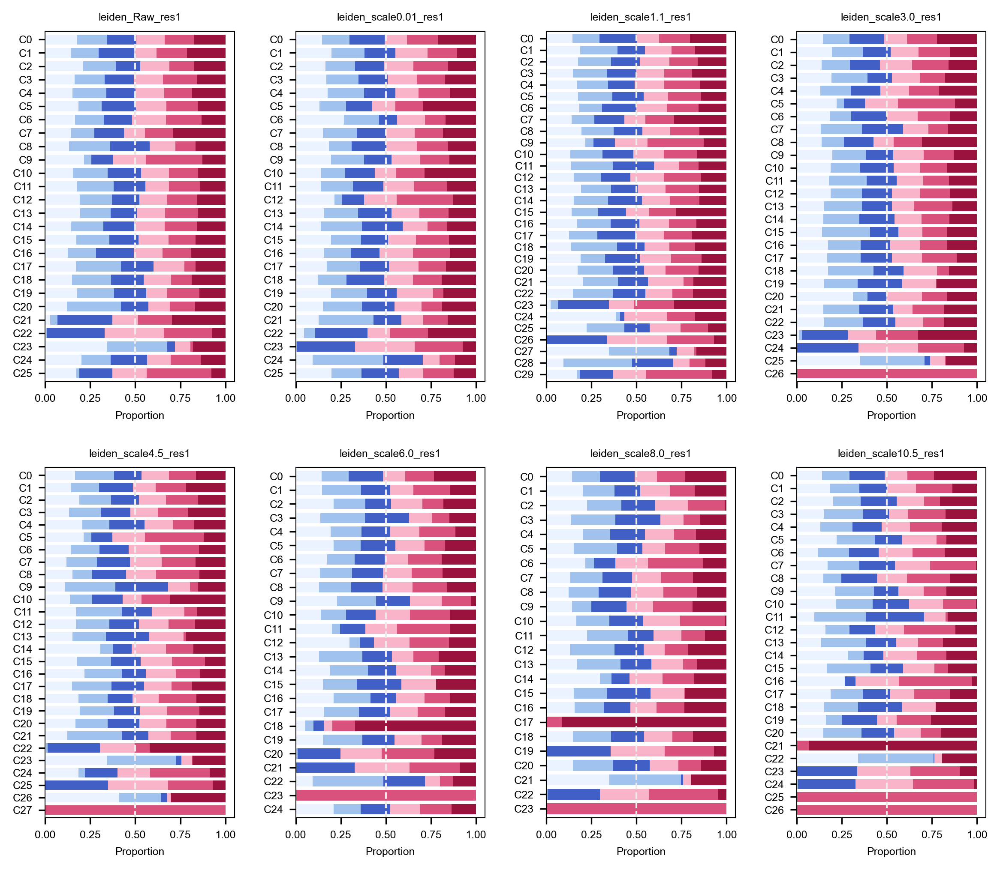

In [17]:
import matplotlib.pyplot as plt

plot_cols = leiden_cols[:8]

fig, axes = plt.subplots(2, 4, figsize=(8, 7))
axes = axes.flatten()

for i, leiden_col in enumerate(plot_cols):
    plot_cell_type_proportion_horizontal(
        adata,
        leiden_col=leiden_col,
        cell_type_col="batch",
        title=leiden_col,
        fontsize=6,
        ax=axes[i],
        show=False,
        legend=False
    )

# Remove unused panels if any
for j in range(len(plot_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## Analysis of AD progression-related signals

In [18]:
from collections import Counter
import pandas as pd

adata.obs['batch2'] = adata.obs['batch'].astype(str)

adata.obs.loc[adata.obs['batch2'] == 'TgCRND81', 'batch2'] = 'Tg1'
adata.obs.loc[adata.obs['batch2'] == 'TgCRND82', 'batch2'] = 'Tg2'
adata.obs.loc[adata.obs['batch2'] == 'TgCRND83', 'batch2'] = 'Tg3'

adata.obs['batch2'] = pd.Categorical(
    adata.obs['batch2'],
    categories=['WT1', 'WT2', 'WT3', 'Tg1', 'Tg2', 'Tg3'],
    ordered=True
)

batch_counts = Counter(adata.obs['batch2'])
print(batch_counts)


Counter({'Tg3': 60369, 'WT3': 59427, 'WT2': 58662, 'Tg2': 58601, 'WT1': 58218, 'Tg1': 53786})


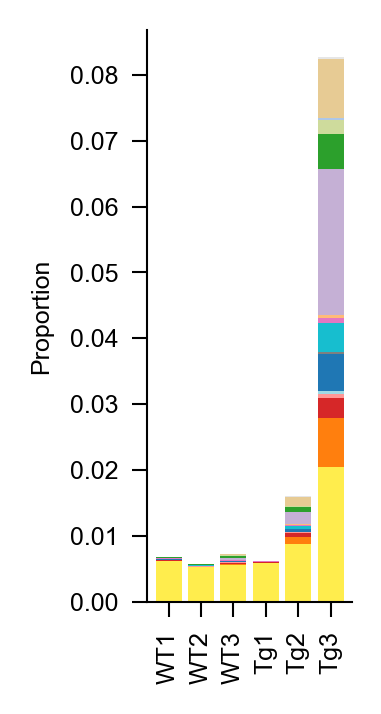

In [19]:
# Calculate cell type proportions in the AD progression-related cluster
df = adata[adata.obs["Domain"] == "Progression-related"].obs[
    ["batch2", "Final_Cell_Type"]
]

count_df = (
    df.groupby(["batch2", "Final_Cell_Type"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# Normalize by the total number of cells in each batch
batch_sizes = adata.obs["batch2"].value_counts()
count_df = count_df.div(batch_sizes, axis=0)

# Keep the same color mapping as in adata.uns, and skip absent cell types
cell_type_categories = list(adata.obs["Final_Cell_Type"].cat.categories)
cell_type_colors = adata.uns["Final_Cell_Type_colors"]

color_map = dict(zip(cell_type_categories, cell_type_colors))
colors = [color_map[cell_type] for cell_type in count_df.columns]

# Plot stacked bar chart
ax = count_df.plot(
    kind="bar",
    stacked=True,
    figsize=(1.5, 2.6),
    color=colors,
    width=0.8,
    linewidth=0.5,
)

plt.xlabel("", fontsize=6)
plt.ylabel("Proportion", fontsize=6)

ax.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for spine in ["bottom", "left"]:
    ax.spines[spine].set_linewidth(0.5)

ax.tick_params(axis="x", labelsize=6, width=0.5)
ax.tick_params(axis="y", labelsize=6, width=0.5)

if ax.get_legend() is not None:
    ax.get_legend().remove()

plt.tight_layout()

pdf_filename = f"{save_path}/Stacked_bar_chart_AD_progression_related_signals.pdf"
plt.savefig(pdf_filename, format="pdf", bbox_inches="tight")

plt.show()

## Analysis of Microglia in the AD progression-related signals

In [20]:
adata_sub = adata[adata.obs['Domain'] == 'Progression-related'].copy()
adata_micro = adata_sub[adata_sub.obs['Final_Cell_Type'] == 'Microglia'].copy()
adata_micro

AnnData object with n_obs × n_vars = 3062 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'Kmeans_scale1.1', 'leiden_scale1.1_res0.8', 'leiden_scale1.1_res1', 'Kmeans_scale3.0', 'leiden_scale3.0_res0.8', 'leiden_scale3.0_res1', 'Kmeans_scale4.5', 'leiden_scale4.5_res0.8', 'leiden_scale4.5_res1', 'Kmeans_scale6.0', 'leiden_scale6.0_res0.8', 'leiden_scale6.0_res1', 'Kmeans_scale8.0', 'leiden_scale8.0_res0.8', 'leiden_scale8.0_res1', 'Kmeans_scale10.5', 'leiden_scale10.5_res0.8', 'leiden_scale10.5_r

In [21]:
sc.tl.rank_genes_groups(
    adata_micro,
    groupby="batch2",
    groups=["Tg3"],
    reference="WT3",
    method="wilcoxon"
)

deg_df = sc.get.rank_genes_groups_df(adata_micro, group="Tg3")
deg_df.to_csv(save_path + '/Microglia_DEG_Tg3_vs_WT3.csv', index=False)
# Show the top 10 differentially expressed genes
deg_df.head(10)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Gfap,25.962593,5.526055,1.310679e-148,4.548055e-146
1,Lyz2,17.111050,3.226336,1.227673e-65,2.130012e-63
2,Apoe,13.512855,0.931968,1.313290e-41,9.114235e-40
3,Vim,13.195875,3.588227,9.267240e-40,4.593903e-38
4,Ctsb,11.972898,0.973038,4.927707e-33,2.137393e-31
5,C4b,11.694477,3.604635,1.360221e-31,5.244406e-30
6,Npc2,11.565764,1.088640,6.144158e-31,1.938203e-29
7,Cd74,10.976471,3.130435,4.959191e-28,1.434033e-26
8,Cd63,10.567142,1.237018,4.231927e-26,1.129599e-24
9,Tyrobp,10.253388,1.424562,1.142667e-24,2.832181e-23


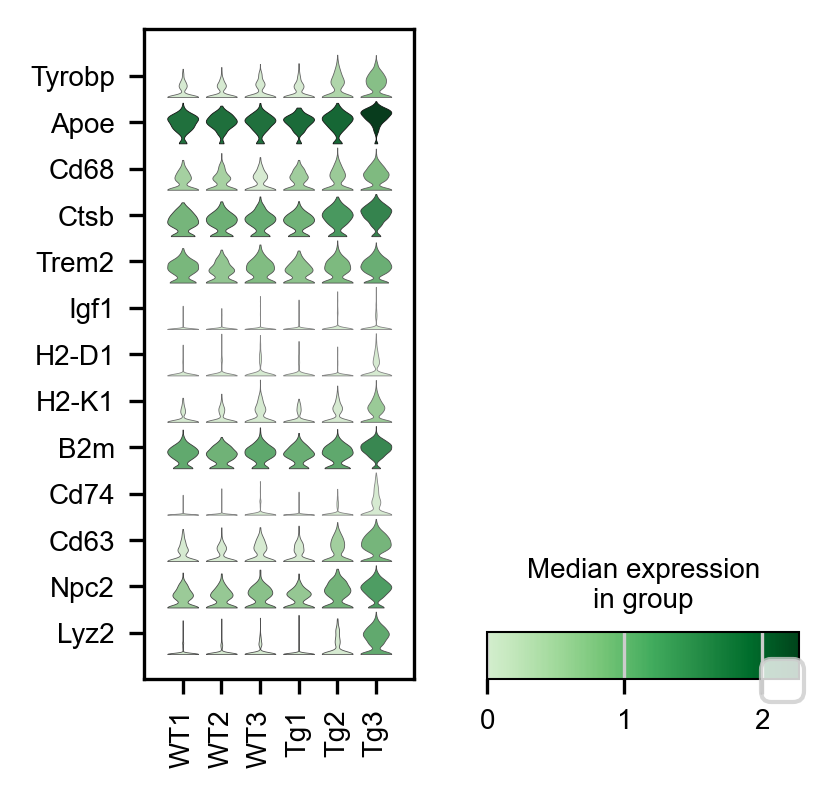

In [22]:
import scanpy as sc
from matplotlib.colors import ListedColormap
green_cmap = ListedColormap(plt.cm.Greens(np.linspace(0.2, 1, 256)))
plt.rcParams.update({'font.size': 8})

genes = ['Tyrobp', 'Apoe', 'Cd68', 'Ctsb', 'Trem2', 'Igf1', 'H2-D1', 'H2-K1', 'B2m', 'Cd74', 'Cd63', 'Npc2', 'Lyz2',] 
fig = sc.pl.stacked_violin(
    adata_micro,
    var_names=genes,
    groupby='batch2',
    figsize=(2.8, 2.85),  
    layer=None,
    swap_axes=True,  
    cmap=green_cmap,  
    show=False  
)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.legend(loc='upper right', bbox_to_anchor=(1.1, 1))  # Move legend to the right
plt.tight_layout()  
plt.savefig(f"{save_path}/Miroglia_DEG_stacked_violin.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [23]:
# Publicly available plaque-induced genes (PIGs)
# Source: Chen, W.T. et al., Spatial Transcriptomics and In Situ Sequencing to Study Alzheimer's Disease. Cell 182, 976-991.e919 (2020).
pig_df = pd.read_csv('./PIG_Cell.csv')
genes_PIGs = set(pig_df['PIGs']).intersection(set(adata.var_names))
len(genes_PIGs)

46

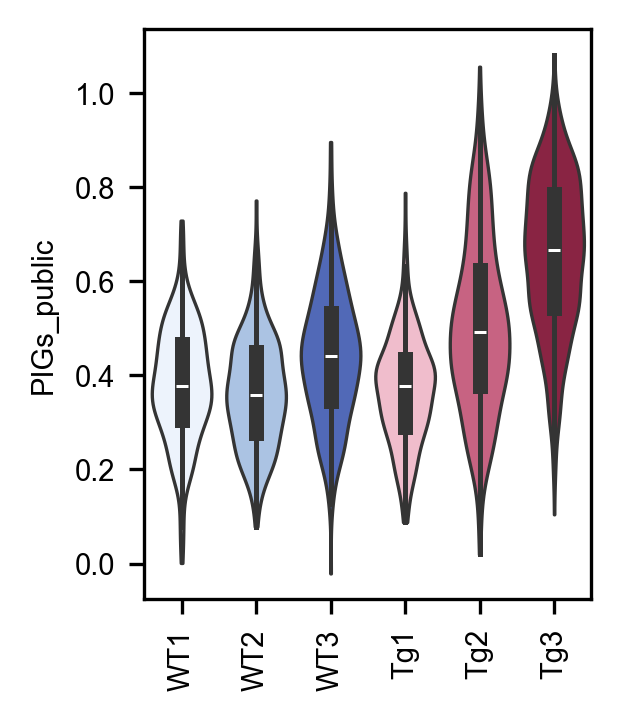

In [24]:
# publicly available plaque-induced genes 
sc.tl.score_genes(adata_micro, genes_PIGs, score_name='PIGs_public')
adata_micro.uns['batch2_colors'] = adata_micro.uns['batch_colors'].copy()

from matplotlib.pyplot import rc_context
with rc_context({"figure.figsize": (2.8, 2.5), "font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.grid": False}):
    sc.pl.violin(adata_micro, keys=['PIGs_public'], groupby='batch2', linewidth = 0.8, rotation=90,  stripplot=False, inner="box")

In [25]:
from scipy.stats import ranksums
tg3_values = adata_micro.obs['PIGs_public'][adata_micro.obs['batch2'] == 'Tg3']
wt3_values = adata_micro.obs['PIGs_public'][adata_micro.obs['batch2'] == 'WT3']

# Perform Wilcoxon rank-sum test
stat, pval = ranksums(tg3_values, wt3_values)
print( 'Statistic, ' + str(stat) +'  P-value, ' + str(pval))

Statistic, 18.871107906743607  P-value, 1.971221699237753e-79


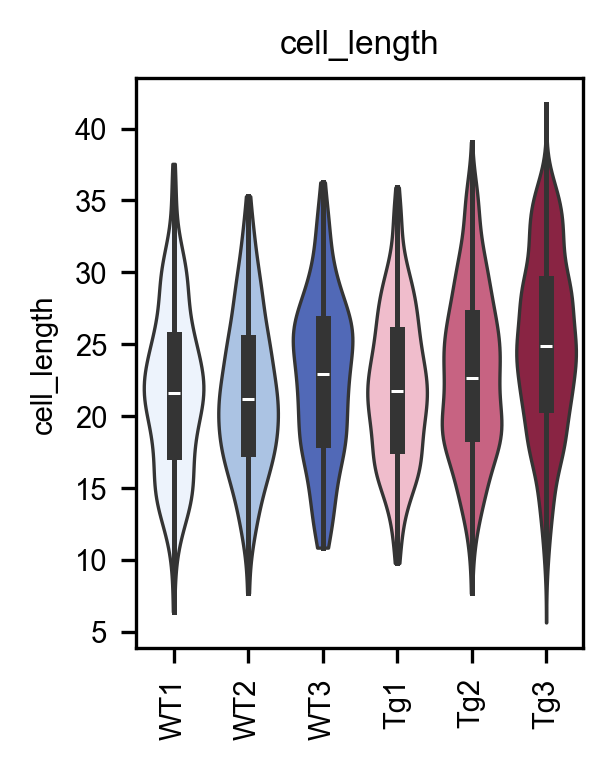

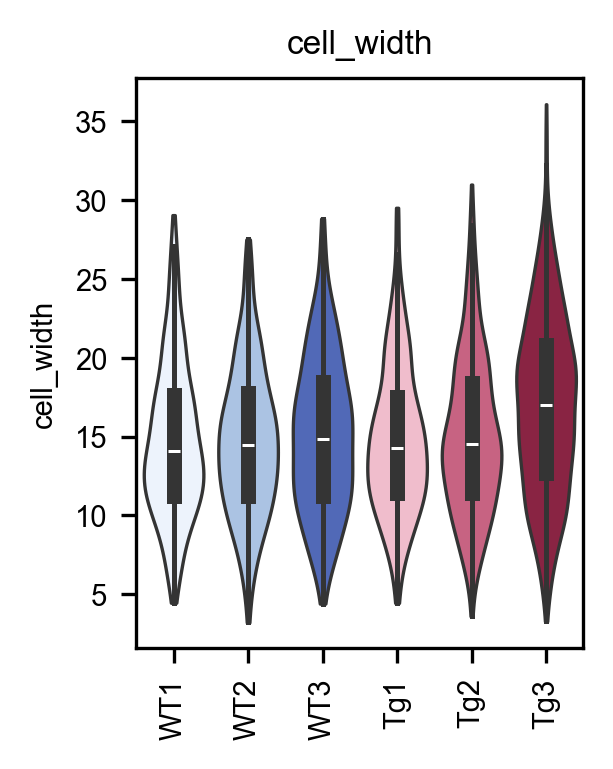

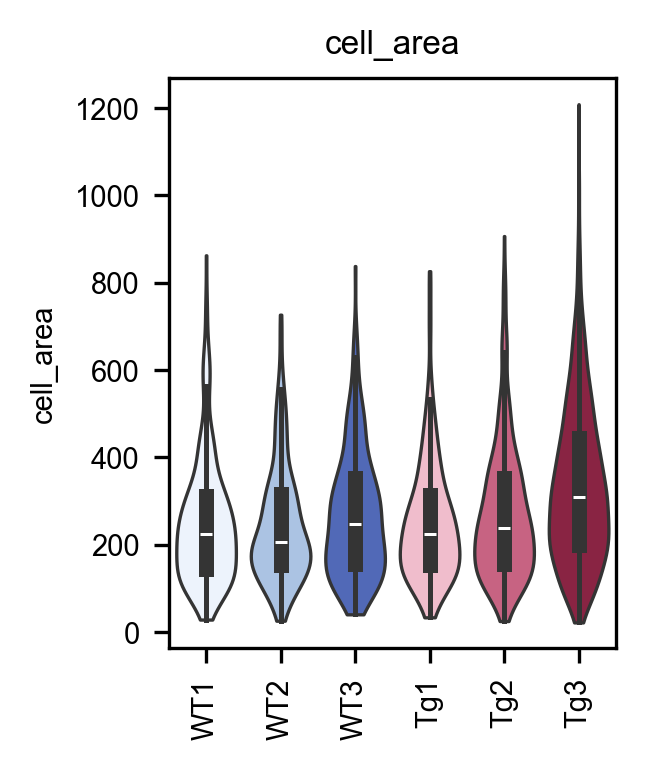

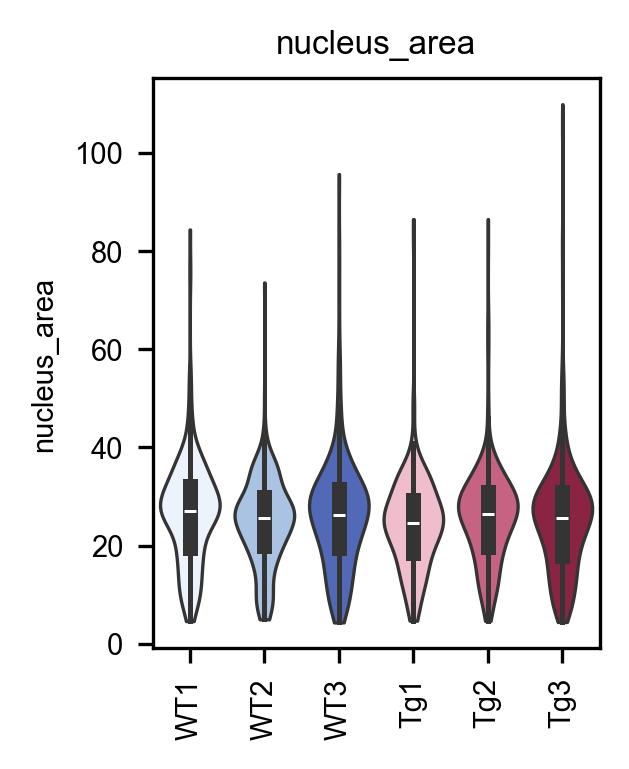

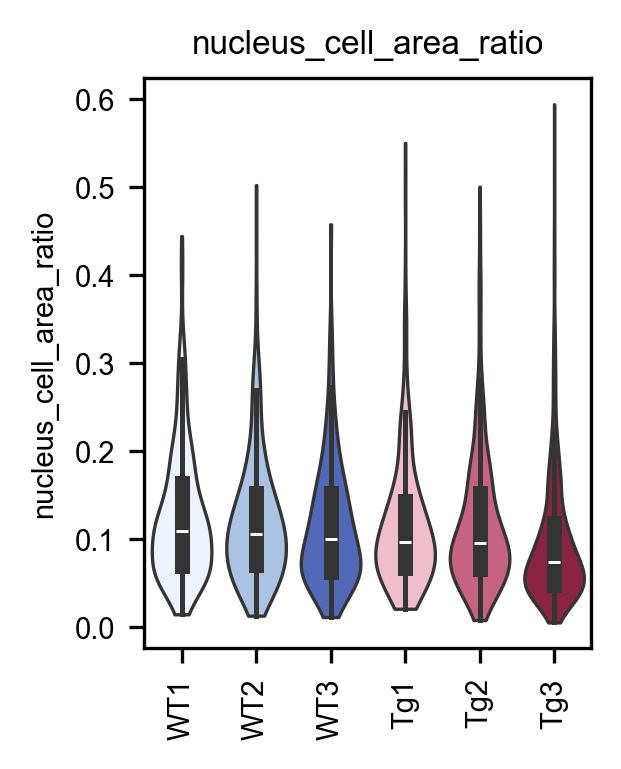

In [26]:
from statsmodels.stats.multitest import multipletests
features = cell_morphology.columns

for feature in features:
    with rc_context({"figure.figsize": (2.8, 2.5), "font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.grid": False}):
        sc.pl.violin(adata_micro, keys=feature, groupby="batch2", rotation=90, linewidth = 0.8, stripplot=False, inner="box", show=False)
        plt.title(feature, fontsize=8)
        plt.tight_layout()
        plt.show()
        plt.close()

In [27]:
from scipy.stats import ranksums
from statsmodels.stats.multitest import multipletests
results = []
for feature in features:
    tg3_values = adata_micro.obs.loc[adata_micro.obs["batch2"] == "Tg3", feature].dropna()
    wt3_values = adata_micro.obs.loc[adata_micro.obs["batch2"] == "WT3", feature].dropna()
    stat, pval = ranksums(tg3_values, wt3_values, alternative='two-sided')
    results.append([feature, tg3_values.mean(), wt3_values.mean(), stat, pval])

stats_df = pd.DataFrame(results, columns=["Feature", "Tg3_mean", "WT3_mean", "Statistic", "P_value"])
stats_df = stats_df[stats_df["Feature"] != "cell_parameter"].copy()
stats_df["P_adj"] = multipletests(stats_df["P_value"], method="fdr_bh")[1]
stats_df = stats_df.sort_values("P_adj")
stats_df

,Feature,Tg3_mean,WT3_mean,Statistic,P_value,P_adj
4,nucleus_cell_area_ratio,0.094853,0.115781,-6.262193,3.795998e-10,1.897999e-09
2,cell_area,335.188586,267.413123,6.101577,1.050271e-09,2.625679e-09
0,cell_length,24.906985,22.642276,5.842710,5.135826e-09,8.559710e-09
1,cell_width,16.929432,15.093628,5.314137,1.071639e-07,1.339549e-07
3,nucleus_area,25.357613,26.056525,-1.292137,1.963099e-01,1.963099e-01


In [28]:
adata.write_h5ad(save_path + "/" + runLabel+ "_analysis.h5ad")